# ticketSF. | Parking enforcement, visualized

**Research question:** When does San Francisco issue the most parking citations?

Dataset: [SFMTA Parking Citations & Fines](https://data.sf.gov/d/ab4h-6ztd) (DataSF, ID `ab4h-6ztd`).

We analyze **2025** as a complete comparison year. The city updates its data, so results can change. This notebook queries *aggregated counts* from the API instead of downloading 24 million rows.

**Important:** Citation counts measure enforcement activity, not the probability that any individual parked car receives a ticket. The data may include non-parking violations; inspect categories before making claims about parking specifically.

In [1]:
# Uncomment in Jupyter if packages are missing:
# %pip install pandas requests matplotlib seaborn
import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

BASE = "https://data.sfgov.org/resource/ab4h-6ztd.json"
META = "https://data.sfgov.org/api/views/ab4h-6ztd.json"
sns.set_theme(style="whitegrid", context="talk")

## 1. Inspect the source schema

Rather than guessing the API field name, find it from the dataset metadata.

In [2]:
meta = requests.get(META, timeout=45)
meta.raise_for_status()
cols = pd.DataFrame([
    {"label": c.get("name", ""), "api_field": c.get("fieldName", ""), "type": c.get("dataTypeName", "")}
    for c in meta.json()["columns"]
])
display(cols[["label", "api_field", "type"]])

matches = cols[cols.label.str.contains("Citation Issued DateTime", case=False, na=False)]
if len(matches) != 1:
    raise ValueError("Date-time column not uniquely identified. Examine columns above and update the selection.")
DATE_FIELD = matches.iloc[0].api_field
print("Using timestamp field:", DATE_FIELD)

,label,api_field,type
0,Citation Number,citation_number,text
1,Citation Issued DateTime,citation_issued_datetime,calendar_date
2,Violation,violation,text
3,Violation Description,violation_desc,text
4,Citation Location,citation_location,text
5,Vehicle Plate State,vehicle_plate_state,text
6,Vehicle Plate,vehicle_plate,text
7,Fine Amount,fine_amount,number
8,Date Added,date_added,calendar_date
9,the_geom,the_geom,point


Using timestamp field: citation_issued_datetime


## 2. Query the entire 2025 year , without downloading every citation

These grouped counts are computed on the city's server. If the API rate-limits you, rerun later or add a Socrata app token.

In [3]:
def api_query(select, group, order):
    params = {
        "$select": select,
        "$where": f"{DATE_FIELD} >= '2025-01-01T00:00:00' AND {DATE_FIELD} < '2026-01-01T00:00:00'",
        "$group": group,
        "$order": order,
        "$limit": 1000,
    }
    response = requests.get(BASE, params=params, timeout=90)
    response.raise_for_status()
    return pd.DataFrame(response.json())

hourly = api_query(
    f"date_extract_hh({DATE_FIELD}) as hour, count(*) as citations",
    "hour", "hour"
)
hourly["hour"] = pd.to_numeric(hourly["hour"])
hourly["citations"] = pd.to_numeric(hourly["citations"])
display(hourly.head())
print("Count of records in hourly results:", f"{hourly.citations.sum():,}")

,hour,citations
0,0,565
1,1,13579
2,2,36830
3,3,11134
4,4,18371


Count of records in hourly results: 1,358,015


## 3. Make the signature visual

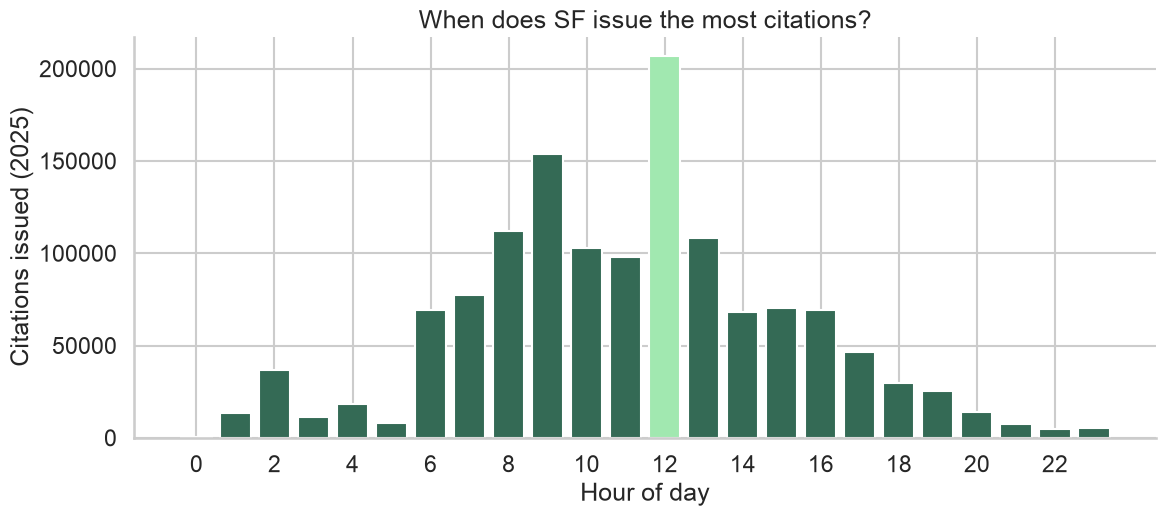

Peak hour: 12


In [4]:
fig, ax = plt.subplots(figsize=(12, 5.5))
colors = ["#a1e8b0" if x == hourly.loc[hourly.citations.idxmax(), "hour"] else "#346a55" for x in hourly.hour]
ax.bar(hourly.hour, hourly.citations, color=colors, width=.8)
ax.set(title="When does SF issue the most citations?", xlabel="Hour of day", ylabel="Citations issued (2025)")
ax.set_xticks(range(0,24,2))
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("ticketsf_hourly_2025.png", dpi=180, bbox_inches="tight")
plt.show()
print("Peak hour:", int(hourly.loc[hourly.citations.idxmax(), "hour"]))

## 4. Analysis notes

The noon hour has 207,051 records; midnight has 565. The peak-to-lowest ratio is 366.5:1. These are counts, not driver-level probabilities. Parking exposure and duration are unavailable. Enforcement timing is a hypothesis, not an established cause.


In [5]:

print(hourly.sort_values("hour").to_string(index=False))

nonzero = hourly[hourly["citations"] > 0]

peak = hourly["citations"].max()
lowest = nonzero["citations"].min()

print(f"\nPeak-to-lowest nonzero ratio: {peak / lowest:.1f}:1")


 hour  citations
    0        565
    1      13579
    2      36830
    3      11134
    4      18371
    5       8017
    6      69238
    7      77618
    8     112046
    9     153896
   10     102970
   11      97726
   12     207051
   13     108432
   14      68317
   15      70286
   16      69339
   17      46452
   18      29869
   19      25135
   20      14194
   21       7304
   22       4549
   23       5097

Peak-to-lowest nonzero ratio: 366.5:1


In [11]:

import requests
import pandas as pd

url = "https://data.sfgov.org/resource/ab4h-6ztd.json"

params = {
    "$select": f"date_trunc_ymd({DATE_FIELD}) AS day, count(*) AS citations",
    "$where": (
        f"{DATE_FIELD} >= '2025-01-01T00:00:00' "
        f"AND {DATE_FIELD} < '2026-01-01T00:00:00'"
    ),
    "$group": "day",
    "$order": "day",
    "$limit": 500
}

response = requests.get(url, params=params, timeout=90)

if not response.ok:
    print(response.status_code, response.text[:1000])
response.raise_for_status()

daily = pd.DataFrame(response.json())
daily["day"] = pd.to_datetime(daily["day"])
daily["citations"] = daily["citations"].astype(int)

# Include all 365 days, even days with zero citations
all_days = pd.date_range("2025-01-01", "2025-12-31")

daily = (
    daily.set_index("day")
    .reindex(all_days, fill_value=0)
    .rename_axis("day")
    .reset_index()
)

daily["day_of_week"] = daily["day"].dt.day_name()

order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

average = (
    daily.groupby("day_of_week")["citations"]
    .mean()
    .reindex(order)
)

print(average.round(0))


day_of_week
Monday       3950.0
Tuesday      4929.0
Wednesday    4748.0
Thursday     4738.0
Friday       4773.0
Saturday     2012.0
Sunday        875.0
Name: citations, dtype: float64


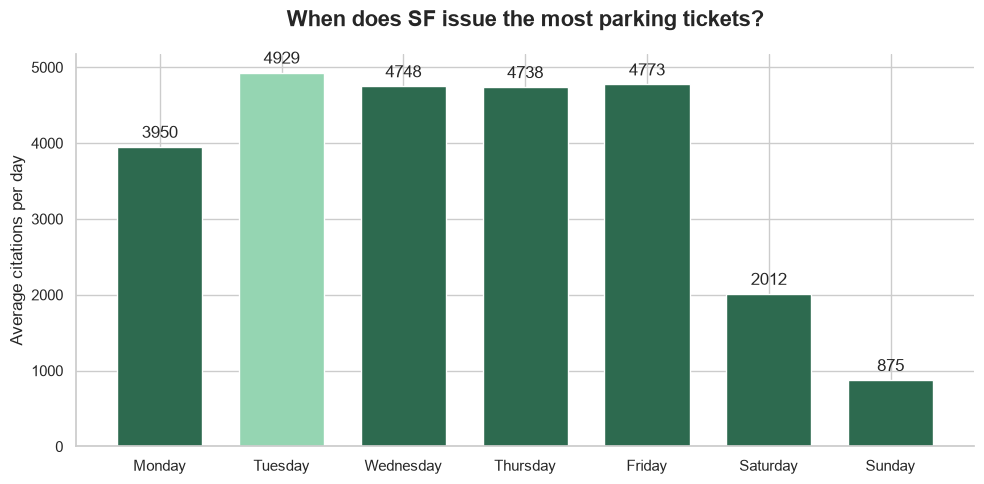

In [12]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(10, 5))

colors = [
    "#2D6A4F" if day != "Tuesday" else "#95D5B2"
    for day in average.index
]

bars = ax.bar(
    average.index,
    average.values,
    color=colors,
    width=0.7
)

ax.bar_label(bars, fmt="%.0f", padding=4)

ax.set_title(
    "When does SF issue the most parking tickets?",
    fontsize=16,
    weight="bold",
    pad=20
)

ax.set_ylabel("Average citations per day")
ax.set_xlabel("")
ax.spines[["top", "right"]].set_visible(False)

plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("ticketsf_weekdays_2025.png", dpi=200)
plt.show()


In [14]:
# Check the available columns directly from the API
metadata = requests.get(
    "https://data.sfgov.org/api/views/ab4h-6ztd.json"
).json()

[
    (col["fieldName"], col["name"])
    for col in metadata["columns"]
    if "violat" in col["fieldName"].lower()
    or "descrip" in col["fieldName"].lower()
]

[('violation', 'Violation'), ('violation_desc', 'Violation Description')]

In [15]:

# Get the 10 most common violations in 2025

params = {
    "$select": "violation_desc, count(*) AS citations",
    "$where": (
        f"{DATE_FIELD} >= '2025-01-01T00:00:00' "
        f"AND {DATE_FIELD} < '2026-01-01T00:00:00' "
        "AND violation_desc IS NOT NULL"
    ),
    "$group": "violation_desc",
    "$order": "citations DESC",
    "$limit": 10
}

response = requests.get(
    "https://data.sfgov.org/resource/ab4h-6ztd.json",
    params=params,
    timeout=90
)

if not response.ok:
    print(response.status_code, response.text[:1000])

response.raise_for_status()

top_violations = pd.DataFrame(response.json())
top_violations["citations"] = top_violations["citations"].astype(int)

print(top_violations.to_string(index=False))


violation_desc  citations
     STR CLEAN     531375
    MTR OUT DT     159391
        RES/OT     116736
     METER DTN      55524
    FAIL DISPL      52018
     NO PLATES      46460
      YEL ZONE      40380
     PRK GRADE      29688
      DRIVEWAY      27543
      RED ZONE      26919


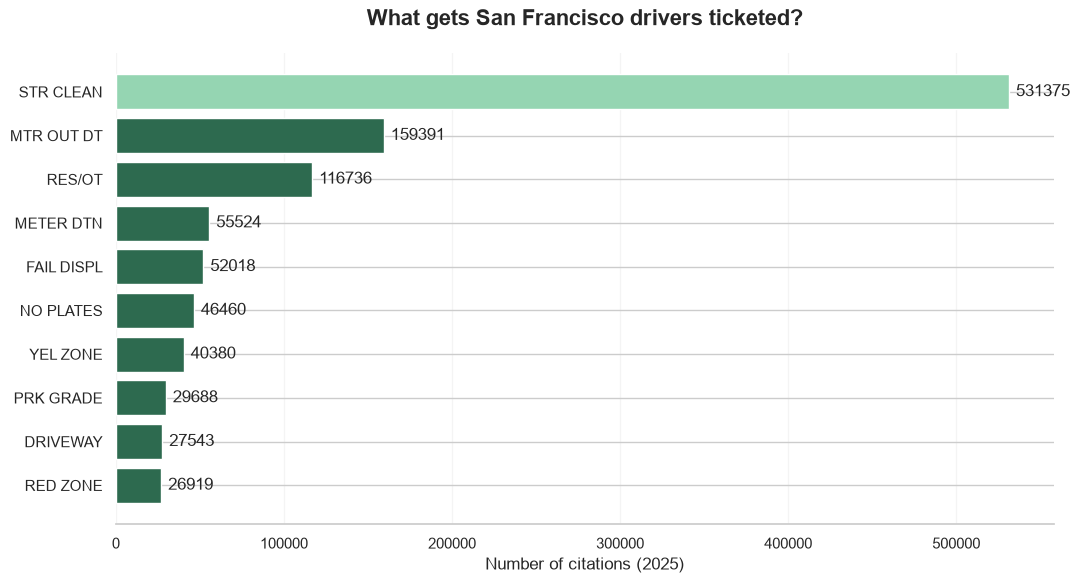

In [17]:


fig, ax = plt.subplots(figsize=(11, 6))

data = top_violations.sort_values("citations")

colors = [
    "#95D5B2" if i == len(data) - 1 else "#2D6A4F"
    for i in range(len(data))
]

bars = ax.barh(
    data["violation_desc"],
    data["citations"],
    color=colors
)

ax.bar_label(bars, padding=5, fmt="%d")

ax.set_title(
    "What gets San Francisco drivers ticketed?",
    fontsize=16,
    weight="bold",
    pad=20
)

ax.set_xlabel("Number of citations (2025)")
ax.set_ylabel("")

ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("ticketsf_violations_2025.png", dpi=200)
plt.show()



In [18]:

# Calculate street cleaning's share of all citations
total_citations = daily["citations"].sum()
street_cleaning = 531375

percentage = street_cleaning / total_citations * 100

print(f"Total 2025 citations: {total_citations:,}")
print(f"Street cleaning citations: {street_cleaning:,}")
print(f"Street cleaning share: {percentage:.1f}%")


Total 2025 citations: 1,358,015
Street cleaning citations: 531,375
Street cleaning share: 39.1%


In [19]:

hourly_total = hourly["citations"].sum()
daily_total = daily["citations"].sum()
top_10_total = top_violations["citations"].sum()

print(f"Hourly total: {hourly_total:,}")
print(f"Daily total: {daily_total:,}")
print(f"Top 10 violations: {top_10_total:,}")
print(f"Totals match: {hourly_total == daily_total}")


Hourly total: 1,358,015
Daily total: 1,358,015
Top 10 violations: 1,086,034
Totals match: True
